We try to approximate the $\mathrm{VIX}$ in the QRH model.

In [2]:
%config InlineBackend.figure_format = 'retina'
%load_ext autoreload
%autoreload 2

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats, integrate, linalg, special
import matplotlib as mpl
from numpy.polynomial.laguerre import laggauss


from fwd_var_curve import xi_curve_smooth
from qrheston import QuadraticRoughHeston
from utils import var_swap_robust


sns.set_theme("talk")
mpl.rcParams["figure.figsize"] = (8, 6)
SEED = 1234

Load market data and set initial forward variance curve

In [4]:
df_spx = pd.read_csv("spx_implied_vol_20230215.csv", index_col=0)
df_vix = pd.read_csv("vix_implied_vol_20230215.csv", index_col=0)
df_spx["Texp_days"] = (365.25 * df_spx["Texp"]).round().astype(int)
df_vix["Texp_days"] = (365.25 * df_vix["Texp"]).round().astype(int)
res_vs = var_swap_robust(ivol_data=df_spx)
w_in = res_vs["vs_mid"] * res_vs["expiries"]
xi_smooth = xi_curve_smooth(res_vs["expiries"], w_in, eps=0.03)["xi_curve"]

/Users/florianbourgey/projects/QuadraticRoughHeston/utils.py:156: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  wbar_flat = quad(PchipInterpolator(np.sort(y_in), sig_in_y**2), y_min, y_max)[0]


In [5]:
spx_expiries_days = [7, 14, 20, 28]
spx_expiries = np.array(spx_expiries_days) / 365.25

vix_expiries_days = [7, 14, 20, 28]
vix_expiries = np.array(vix_expiries_days) / 365.25

Set QRH parameters

In [6]:
params0 = {"al": 0.568, "lam": 9.68, "nu": 0.572, "c": 8.1e-3}
qrh = QuadraticRoughHeston(**params0, xi0=xi_smooth)

In [7]:
paths = 2 * 10**5
steps = 300
qrh_sim = qrh.simulate(paths=paths, steps=steps, expiries=spx_expiries, output="all")

### Check distribution of $\chi_k$

Let us check the distribution of the 
$\chi_k = \int_{(k-1)\Delta}^{k\Delta} \sqrt{V_s} \, dW_s$
with $\Delta = T/n$

In [29]:
T = spx_expiries[0]
chi = qrh_sim[T]["chi"]
print(chi.shape)

(300, 200000)


In [30]:
Delta = T / steps

tmp_var = np.array(
    [
        integrate.quad(lambda u: qrh.xi0(u), (k - 1) * Delta, k * Delta)[0]
        for k in range(1, steps + 1)
    ]
)

PDF plot

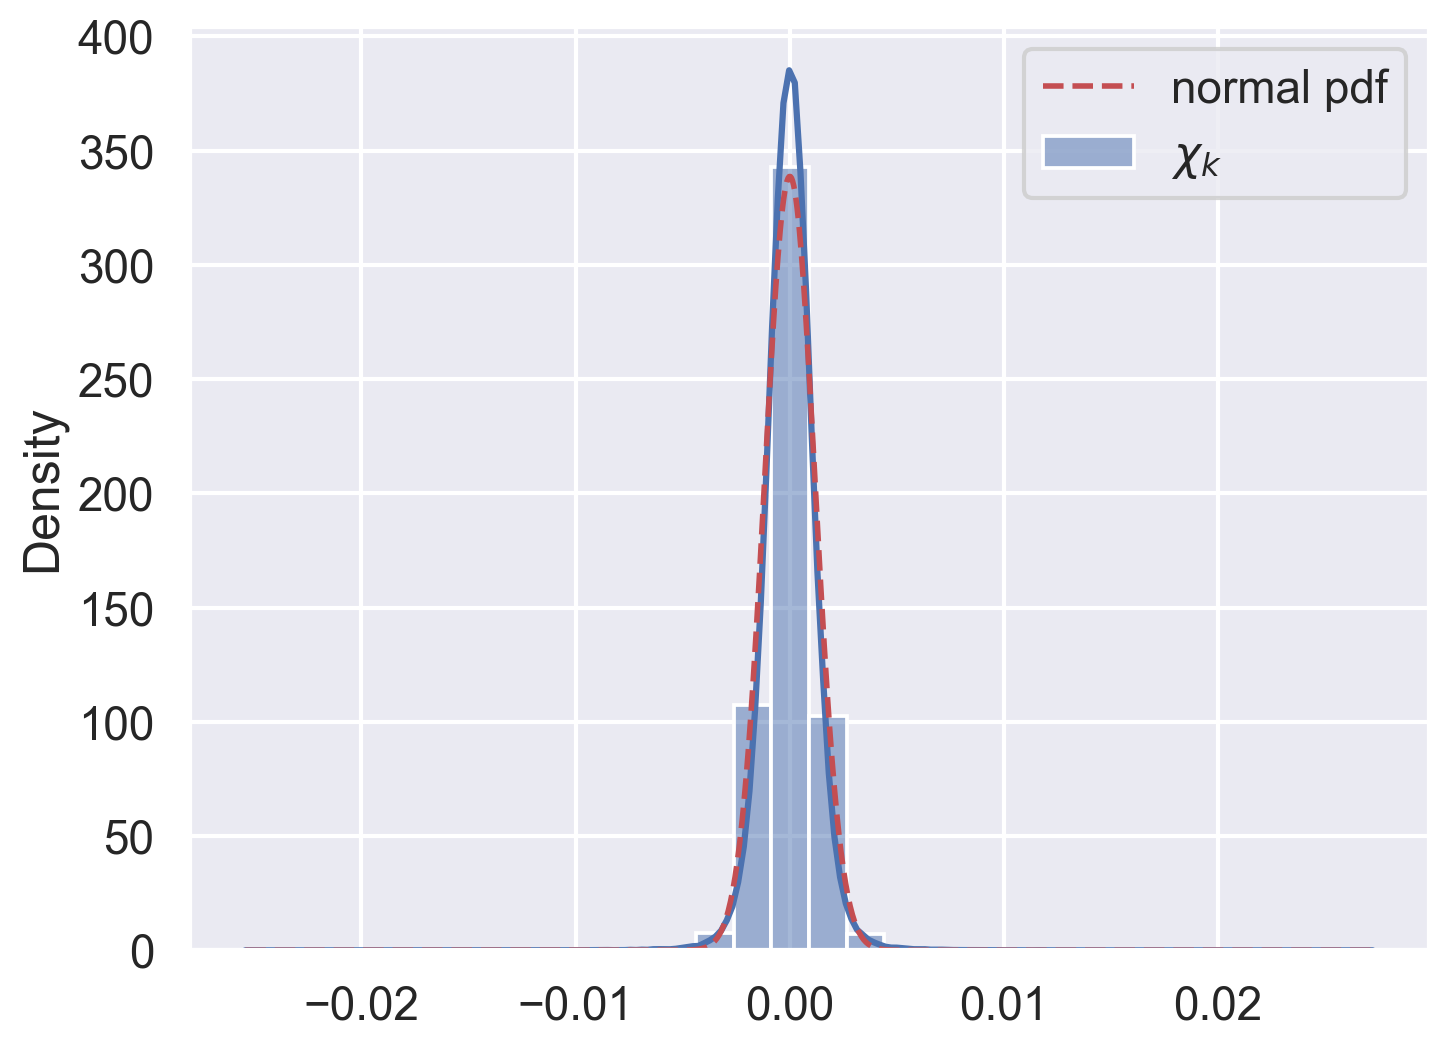

In [31]:
k = 200
chi_k = chi[100, :]
tab_x = np.linspace(chi_k.min(), chi_k.max(), 1000)
mean = chi_k.mean()
std = chi_k.std()

fig, ax = plt.subplots()
sns.histplot(chi_k, bins=30, kde=True, stat="density", ax=ax, label="$\\chi_k$")
ax.plot(
    tab_x, stats.norm.pdf(tab_x, loc=mean, scale=std), "r--", lw=2, label="normal pdf"
)
ax.legend()
plt.show()

Q-Q plot

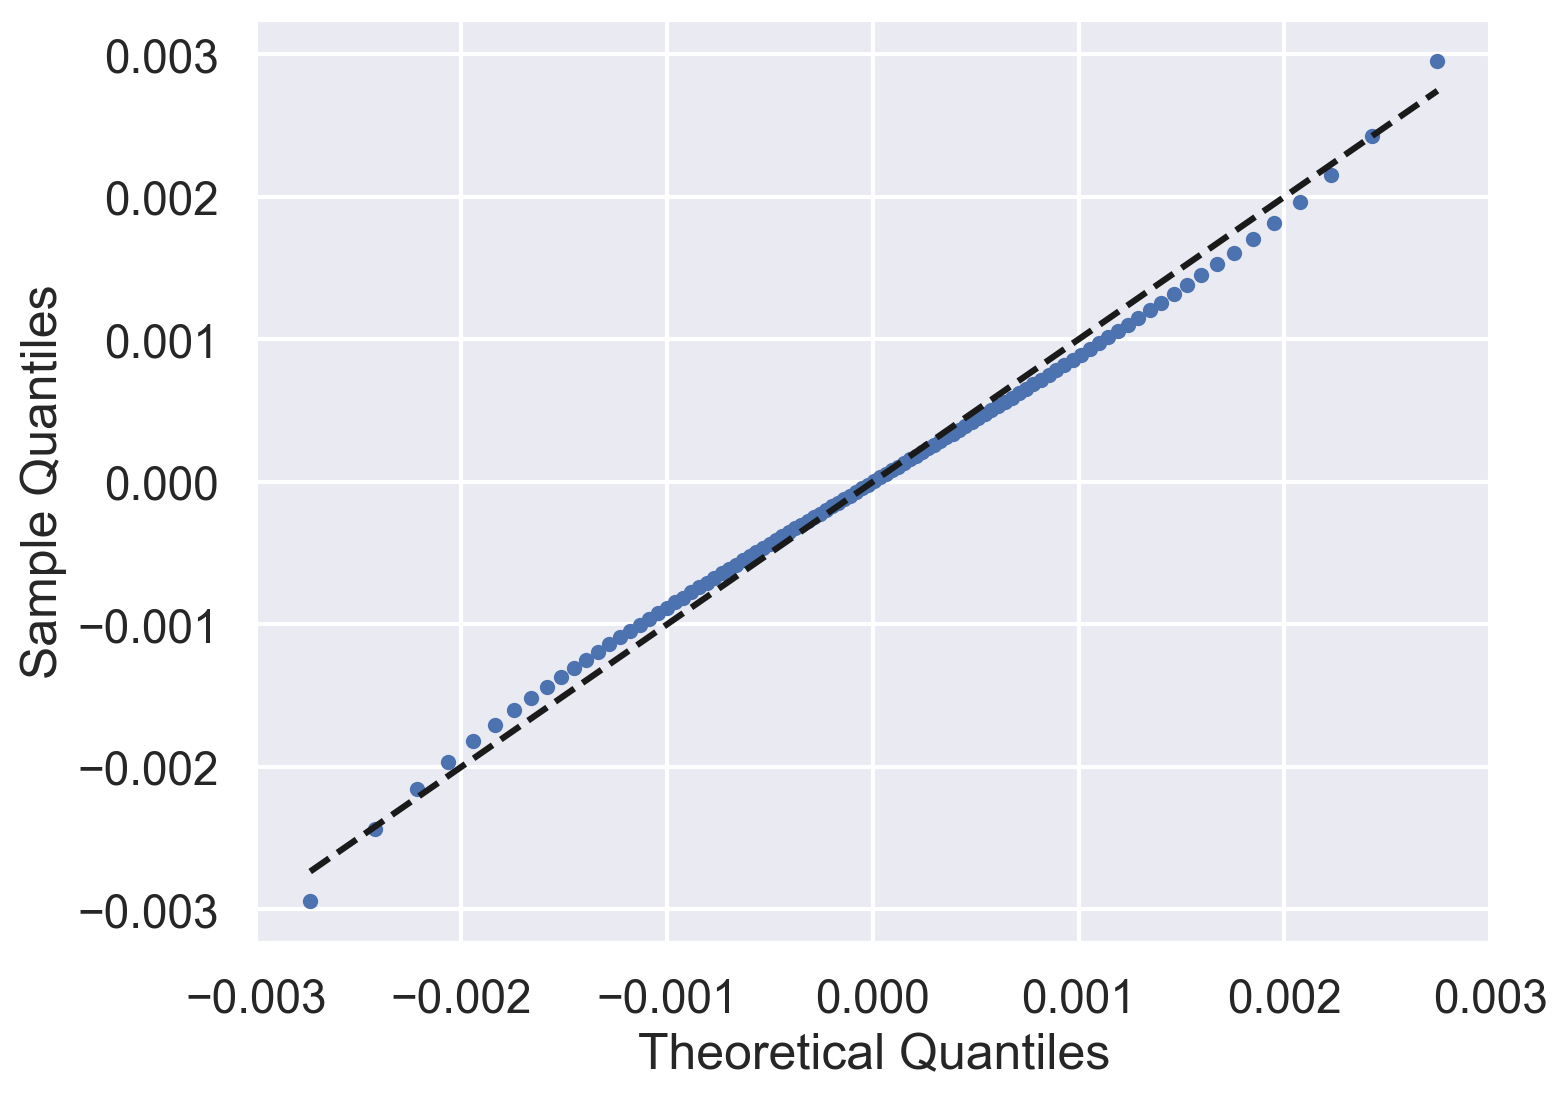

In [32]:
quantiles = np.linspace(1e-2, 1 - 1e-2, 101)
chi_k_quantiles = np.quantile(chi_k, q=quantiles)
normal_quantiles = stats.norm.ppf(quantiles, loc=mean, scale=std)

fig, ax = plt.subplots()
ax.plot(normal_quantiles, chi_k_quantiles, ".")
ax.plot(normal_quantiles, normal_quantiles, "k--")
ax.set_xlabel("Theoretical Quantiles")
ax.set_ylabel("Sample Quantiles")
plt.show()

### Gaussian approximation

From our paper "The SSR under Quadratic Rough Heston",
observe that 

$$
\mathrm{VIX}_T^2 \approx a_T + b_T^\top  \chi + \chi^\top C_T \chi
$$

where 

- $\chi = (\chi_i)_{1 \leq i \leq n}$ with 
$\chi_i = \int_{(i-1)\Delta}^{i\Delta} \sqrt{V_s} \, dW_s$

- $b_T = (b_{i}(T))_{1 \leq i \leq n}$ 

- $C_T = (c_{ij}(T))_{1 \leq i,j \leq n}$

and

$$
\begin{align*}
w(u) &= 1 + K_0(\delta - u) \\
a_T &= \frac{1}{\delta} \int_{0}^{\delta} \left( y_0(T+u)^2 + c \right) w(u) \, du \\
b_i(T) &= \frac{2}{\delta} \int_{0}^{\delta} y_0(T+u) \, a_i(T+u) \, w(u) \, du \\
c_{ij}(T) &= \frac{1}{\delta} \int_{0}^{\delta} a_i(T+u) \, a_j(T+u) \, w(u) \, du
\end{align*}
$$

We approximate the $(\chi_i)_{1 \leq i \leq n}$ independent centered normal random variables
with variance $\mathrm{Var}(\chi_i) = \Delta \overline{\xi}_i$ 
where we recall that
$$
\overline{\xi}_i = \frac{1}{\Delta}\int_{(i-1)\Delta}^{i\Delta} \xi_0(u) \, du
$$


**Characteristic function of quadratic normal**

Let $Z \sim \mathcal{N}(0, I_n)$ and $C \in \mathbb{R}^{n \times n}$ a positive semi-definite matrix. The characteristic function of the quadratic 
form $S = a + b^\top Z + Z^\top C Z$ is given by
$$
\varphi_S(t) 
= \mathbb{E}[e^{itS}]
= e^{i a t} \times \mathrm{det}(I_n - 2 i t C)^{-1/2} \times \exp\left( -\frac{t^2}{2} b^\top (I_n - 2 i t C)^{-1} b \right)
$$

Note that as $C$ is a covariance matrix, diagonalization gives
$$
    C = U \Lambda U^\top,
$$
with $U$ orthonormal and $\Lambda = \mathrm{diag}(\lambda_1, \ldots, \lambda_n)$
and $\lambda_i \geq 0$ for all $i$.

In particular, we have

$$
    (I_n - 2 i t C)^{-1} = U \mathrm{diag}\left(\frac{1}{1 - 2 i t \lambda_j}\right)_{j=1}^{n} U^\top
$$

and

$$
    \mathrm{det}(I_n - 2 i t C) = \prod_{j=1}^{n} (1 - 2 i t \lambda_j)
$$

---

To apply this to $\mathrm{VIX}_T^2$, we set $D=\Delta\times\mathrm{diag}(\overline{\xi}_1, \ldots, \overline{\xi}_n)$ and set $\chi = D^{1/2} Z$.

Then, replace $b$ with $D^{1/2} b_T$ and $C$ with $D^{1/2} C_T D^{1/2}$.

Pre-compute parameters: $a$, the vector $b$, and the matrix $C$

In [119]:
# set parameters
expiry = spx_expiries[1]
vix_expiry_mc = qrh_sim[expiry]["vix"]
delta_vix = 1.0 / 12.0
Delta = expiry / steps
n_vix = 10
u_quad = np.linspace(0.0, delta_vix, n_vix + 1)

In [120]:
# sanity check
assert np.allclose((u_quad[1] - u_quad[0]) / delta_vix, 1 / n_vix)

In [121]:
# pre-compute quantities on the integral grid


def func_a(k, u):
    return np.sqrt(
        (qrh.integral_K00(u - (k - 1) * Delta) - qrh.integral_K00(u - k * Delta))
        / Delta
    )


func_a_quad = np.array([func_a(k, expiry + u_quad) for k in np.arange(1, steps + 1)])
weights_quad = np.array([1.0 + qrh.integral_bigK0(delta_vix - u) for u in u_quad])
y0_quad = qrh.y0(expiry + u_quad)
tab_xi = (
    np.array(
        [
            integrate.quad(lambda u: qrh.xi0(u), (k - 1) * Delta, k * Delta)[0]
            for k in range(1, steps + 1)
        ]
    )
    / Delta
)

Compute scalar $a$

In [122]:
a_quad = (y0_quad**2 + qrh.c) * weights_quad
a_scalar = 0.5 * np.sum(a_quad[:-1] + a_quad[1:]) / n_vix

Compute vector $b$

In [123]:
b_vec = np.zeros(steps)
for i in range(steps):
    b_vec_quad = y0_quad * func_a_quad[i, :] * weights_quad
    b_vec[i] = 0.5 * np.sum(b_vec_quad[:-1] + b_vec_quad[1:]) * 2.0 / n_vix
b_vec *= np.sqrt(Delta * tab_xi)  # rescale variance for chi

Compute matrix $C$

In [124]:
mat_C = np.zeros((steps, steps))
for i in range(steps):
    for j in range(steps):
        if i <= j:
            c_quad = func_a_quad[i, :] * func_a_quad[j, :] * weights_quad
            mat_C[i, j] = 0.5 * np.sum(c_quad[:-1] + c_quad[1:]) / n_vix
        else:
            mat_C[i, j] = mat_C[j, i]
        # rescale variance for chi
        mat_C[i, j] *= Delta * np.sqrt(tab_xi[i] * tab_xi[j])

Perform SVD on matrix $C$

In [125]:
U, S, U_tranpose = linalg.svd(mat_C)
U_b = U.T @ b_vec


def inverse_shift_id(t):
    return U @ np.diag(1.0 / (1.0 - 2j * t * S)) @ U.T


def det_shift_id(t):
    return np.prod(1.0 - 2j * t * S)

Define characteristic function of VIX squared quadratic Gaussian approximation

In [126]:
def charfunc_quadratic_normal(t, a, b, C):
    """
    Characteristic function of S = a + b^T * Z + Z^T * C * Z
    where Z is a standard normal random vector
    C = covariance matrix and b n-dim vector.
    """
    id = np.eye(len(b))
    shift_id = id - 2j * t * C
    inv = linalg.solve(shift_id, id)
    det = linalg.det(shift_id)
    factor = np.exp(1j * a * t) * det ** (-0.5)
    return factor * np.exp(-0.5 * t**2 * b.T @ inv @ b)


def charfunc_quadratic_normal_svd(t, a):
    """
    Characteristic function of S = a + b^T * Z + Z^T * C * Z
    where Z is a standard normal random vector
    C = covariance matrix and b n-dim vector.
    with SVD on matrix C.
    """
    factor = np.exp(1j * a * t) * det_shift_id(t) ** (-0.5)
    return factor * np.exp(-0.5 * t**2 * np.sum(U_b**2 / (1.0 - 2j * t * S)))

Plot of $t \mapsto \varphi_{\text{VIX}_T^2}(it)$. 
This is a real-valued function.

In [127]:
ts = np.linspace(0.0, 300, 201)
phi_vix2_i_ts = np.array(
    [charfunc_quadratic_normal(t=1j * t, a=a_scalar, b=b_vec, C=mat_C) for t in ts]
)
phi_vix2_i_ts_svd = np.array(
    [charfunc_quadratic_normal_svd(t=1j * t, a=a_scalar) for t in ts]
)

In [128]:
charfunc_quadratic_normal_svd(1j * 1e4, a_scalar)

np.complex128(6.180342947652252e-102+0j)

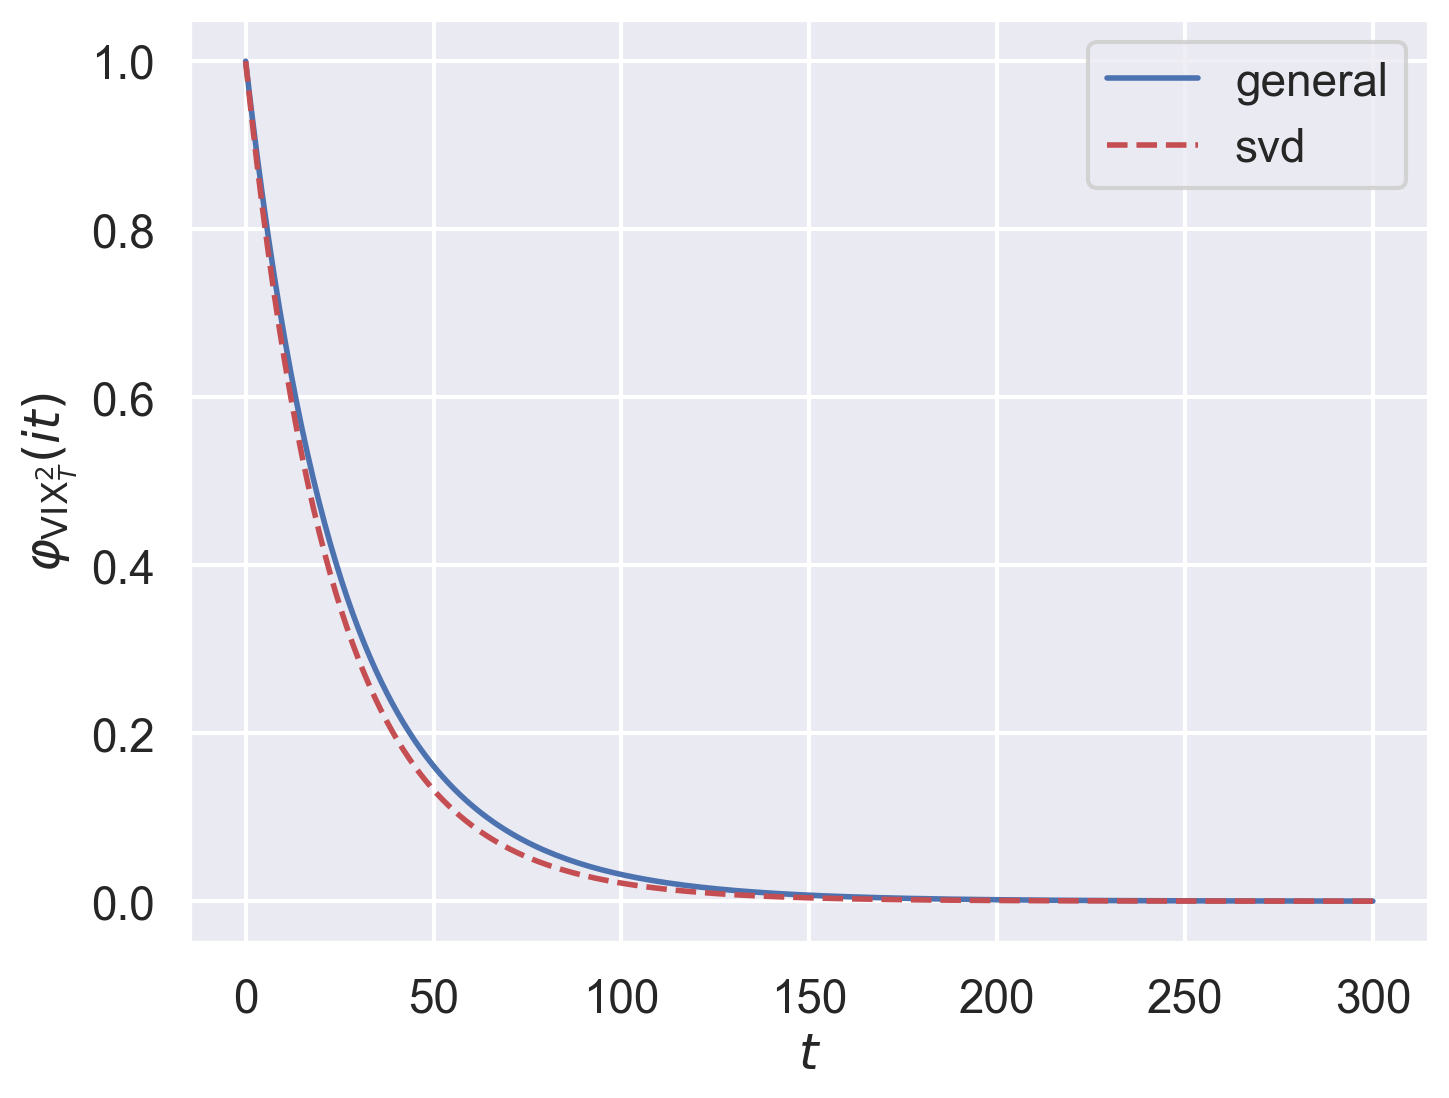

In [129]:
fig, ax = plt.subplots()
ax.plot(ts, np.real(phi_vix2_i_ts), "b-", lw=2, label="general")
ax.plot(ts, np.real(phi_vix2_i_ts_svd), "r--", lw=2, label="svd")
ax.set_xlabel("$t$")
ax.set_ylabel("$\\varphi_{\\mathrm{VIX}_T^2}(it)$")
ax.legend()
plt.show()

/var/folders/cx/lqg_nbts2gd5hgdpftngz4z80000gn/T/ipykernel_35855/1864920488.py:2: RuntimeWarning: invalid value encountered in divide
  ax.plot(ts, (1 - np.real(phi_vix2_i_ts)) / ts ** (3 / 2), "b-", lw=2, label="general")
/var/folders/cx/lqg_nbts2gd5hgdpftngz4z80000gn/T/ipykernel_35855/1864920488.py:3: RuntimeWarning: invalid value encountered in divide
  ax.plot(ts, (1 - np.real(phi_vix2_i_ts_svd)) / ts ** (3 / 2), "r--", lw=2, label="svd")


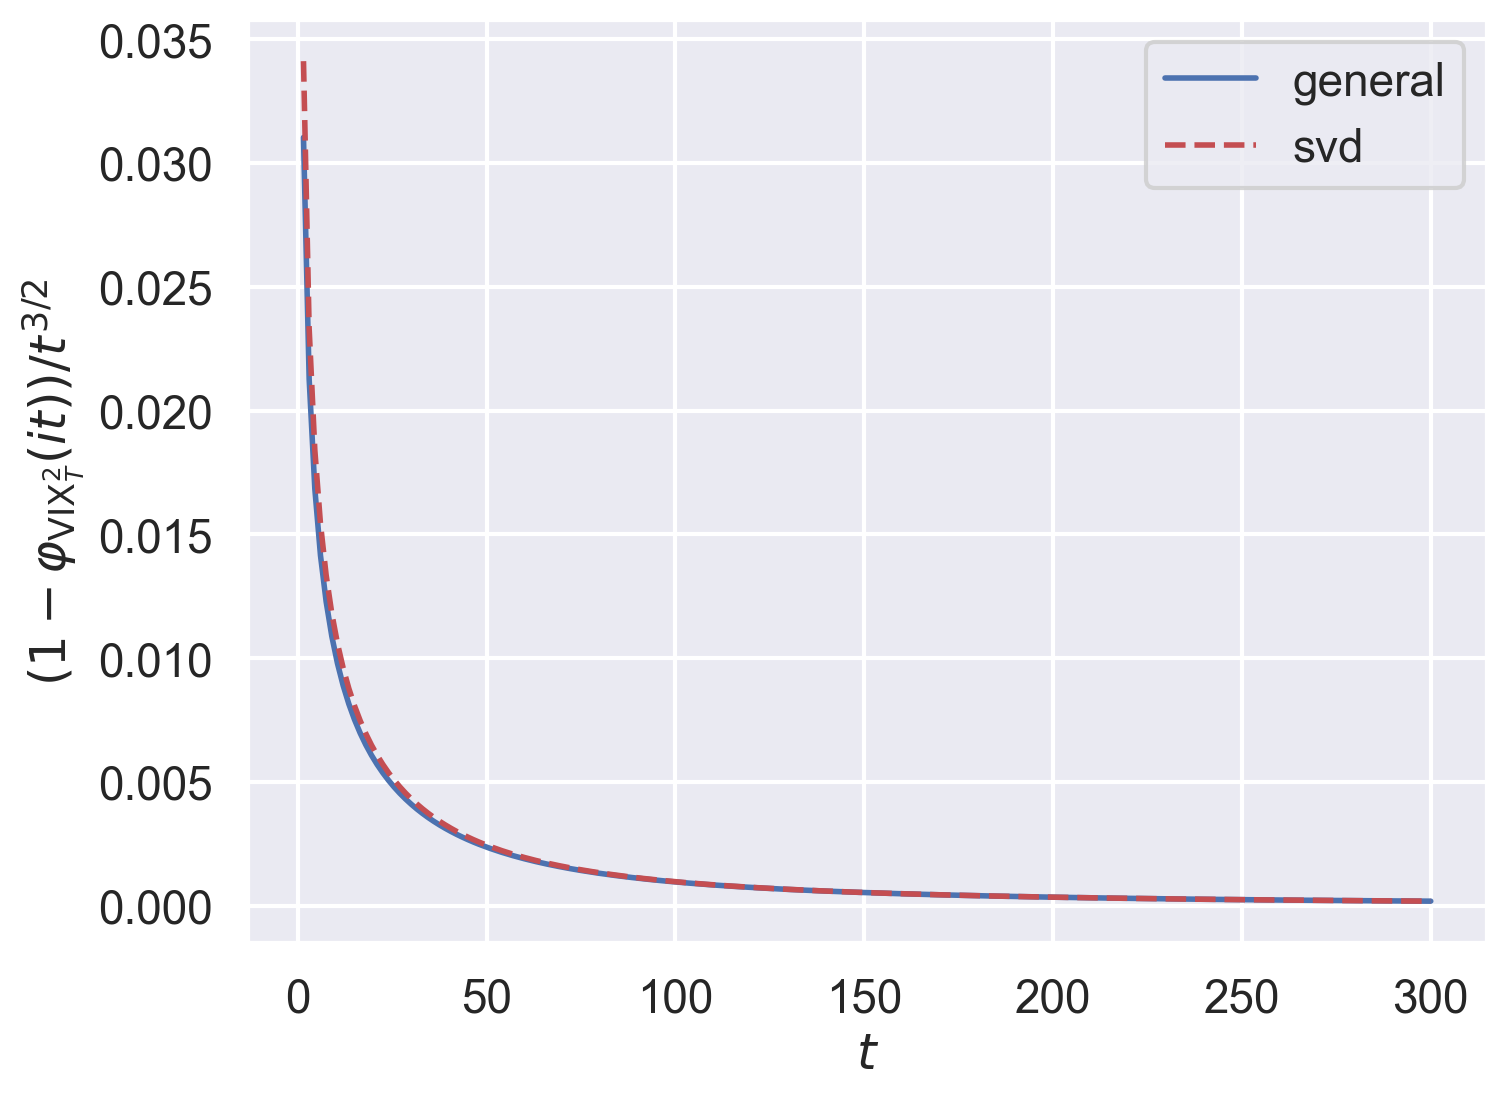

In [130]:
fig, ax = plt.subplots()
ax.plot(ts, (1 - np.real(phi_vix2_i_ts)) / ts ** (3 / 2), "b-", lw=2, label="general")
ax.plot(ts, (1 - np.real(phi_vix2_i_ts_svd)) / ts ** (3 / 2), "r--", lw=2, label="svd")
ax.set_xlabel("$t$")
ax.set_ylabel("$(1 - \\varphi_{\\mathrm{VIX}_T^2}(it)) / t^{3/2}$")
ax.legend()
plt.show()

In [131]:
charfunc_quadratic_normal(3.0, a_scalar, b_vec, mat_C)

np.complex128(0.992523787939225+0.1173463868019157j)

In [132]:
charfunc_quadratic_normal_svd(3.0, a_scalar)

np.complex128(0.9909949063892358+0.12929156334166747j)

In [162]:
# TODO: add COS method

In [133]:
def pdf_vix2(x, a, b, C):
    return (
        integrate.quad(
            lambda t: np.real(
                np.exp(-1j * t * x) * charfunc_quadratic_normal(t, a, b, C)
            ),
            0.0,
            1e4,
        )[0]
        / np.pi
    )


def pdf_vix2_svd(x, a):
    return (
        integrate.quad(
            lambda t: np.real(
                np.exp(-1j * t * x) * charfunc_quadratic_normal_svd(t, a)
            ),
            0.0,
            2e5,
        )[0]
        / np.pi
    )


def pdf_vix(x, a, b, C):
    return 2.0 * x * pdf_vix2(x**2, a, b, C)


def pdf_vix_svd(x, a):
    return 2.0 * x * pdf_vix2_svd(x**2, a)

In [134]:
qrh_sim[expiry]["vix"]

array([0.2825456 , 0.16467662, 0.1687667 , ..., 0.18916682, 0.17455794,
       0.18874141], shape=(200000,))

In [135]:
xs = np.linspace(np.min(vix_expiry_mc), 0.25, 101)

In [136]:
# pdf_vix_xs = np.zeros_like(xs)
# for i in range(len(xs)):
#     print(f"i={i}")
#     pdf_vix_xs[i] = pdf_vix(xs[i], a_scalar, b_vec, mat_C)

In [137]:
pdf_vix_xs_svd = np.zeros_like(xs)
for i in range(len(xs)):
    # print(f"i={i}")
    pdf_vix_xs_svd[i] = pdf_vix_svd(xs[i], a_scalar)

/var/folders/cx/lqg_nbts2gd5hgdpftngz4z80000gn/T/ipykernel_35855/1191684153.py:16: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  integrate.quad(


From a direct change of variables,
we have $f_{\mathrm{VIX}_T}(x) = 2 x \, f_{\mathrm{VIX}_T^2}(x^2)$ for all $x \geq 0$.

Gauss-Laguerre on 
$$
    f(x) = \frac{1}{\pi} \int_0^\infty \real\left( e^{-itx} \varphi(t) \right) \, dt
$$

In [138]:
# t_lag, w_lag = laggauss(180)
# cf_lag = np.array([charfunc_quadratic_normal_svd(t, a=a_scalar) for t in t_lag])
# pdf_vix_xs_lag = np.zeros_like(xs)
# for i, x in enumerate(xs):
#     pdf_vix_xs_lag[i] = (
#         np.sum(w_lag * np.real(cf_lag * np.exp(t_lag * (1.0 - 1j * x)))) / np.pi
#     )

# pdf_vix_xs_lag *= 2 * xs

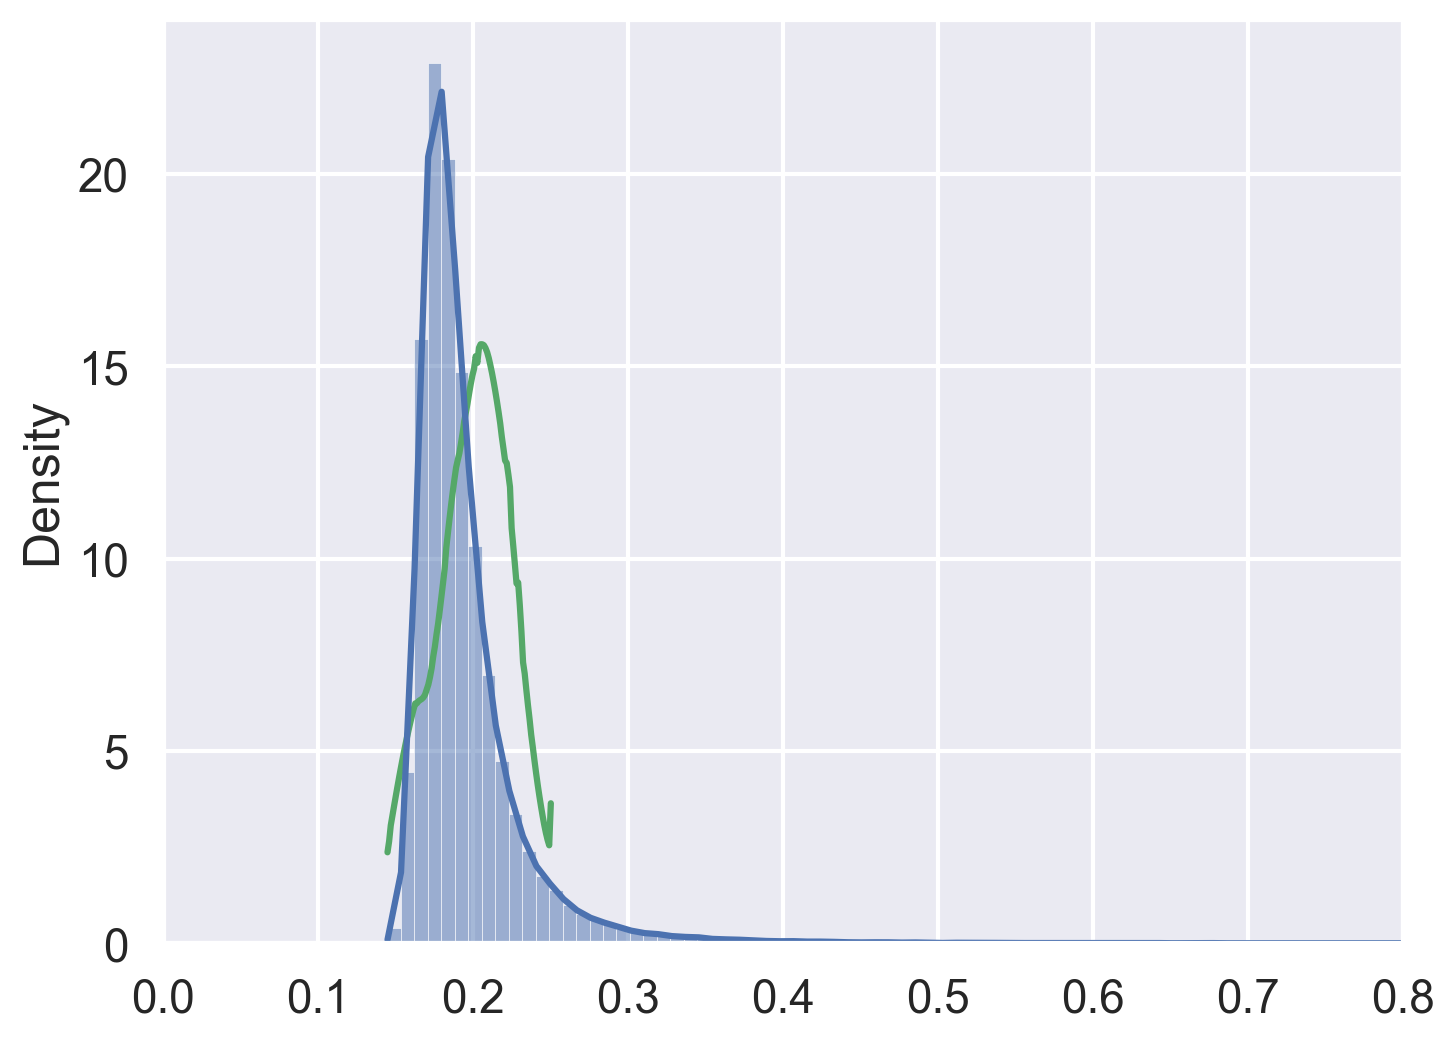

In [139]:
fig, ax = plt.subplots()
# ax.plot(xs, pdf_vix_xs_lag, ".r")
ax.plot(xs, pdf_vix_xs_svd, "-g")
sns.histplot(vix_expiry_mc, bins=200, kde=True, stat="density", ax=ax)
ax.set_xlim(0.0, 0.8)
plt.show()

Compute VIX futures price using the representation

$$
\mathbb{E}[\text{VIX}_T] = \frac{1}{2\sqrt{\pi}}
\int_0^\infty \frac{1-\varphi_{\text{VIX}_T^2}(it)}{t^{3/2}} \, dt.
$$

In [151]:
# Monte Carlo price of vix futures
vix_fut_mc = vix_expiry_mc.mean()
error_mc = 1.95 * vix_expiry_mc.std() / np.sqrt(paths)

print(vix_fut_mc, "+/-", error_mc)

0.19464911863307577 +/- 0.00016885821400919074


In [141]:
# direct integration
# it seems that the integration is sensitive to the upper bound
def integral_vix_fut(a):
    def integrand(t):
        cf = charfunc_quadratic_normal_svd(1j * t, a)
        return np.real((1.0 - cf) / t ** (1.5))

    integral = integrate.quad(integrand, 0.0, 1.5e4)[0]
    integral /= 2.0 * np.sqrt(np.pi)
    return integral


def integral_vix_fut_change(a):
    def integrand(z):
        cf = charfunc_quadratic_normal_svd(1j * (z / (1 - z)) ** 2, a)
        return 2.0 * np.real((1.0 - cf) / z ** (2))

    integral = integrate.quad(integrand, 0.0, 0.99)[0]
    integral /= 2.0 * np.sqrt(np.pi)
    return integral

In [142]:
integral_vix_fut(a_scalar)

np.float64(0.20160000990248425)

In [143]:
integral_vix_fut_change(a_scalar)

np.float64(0.20050771389832167)

It appears there is another (Laplace-transform) representation 

$$
x^{3/2} = \frac{3}{4\sqrt{\pi}} \int_0^\infty (e^{-x t} -1 + x t) \, t^{-5/2} \, dt
$$

In [ ]:
x = 0.4
p = 1.5


def integrand(t):
    return (3 / (4 * np.sqrt(np.pi))) * (np.exp(-x * t) - 1 + x * t) / t ** (5 / 2)


integrate.quad(integrand, 0, np.inf)[0] - x**p

-1.7318837475244209e-09

Trying with Gauss-Laguerre quadrature

$$
\mathbb{E}[\text{VIX}_T] = \frac{\sqrt{a}}{2\sqrt{\pi}}
\int_0^\infty \frac{e^{s} - \varphi_{\text{VIX}_T^2}(is/a)}{s^{3/2}} e^{-s} \, ds
= \
$$

In [159]:
x_lag, w_lag = laggauss(100)


def foo(t):
    factor = np.prod(1.0 + 2 * t * S) ** (-0.5)
    return factor * np.exp(0.5 * t**2 * np.sum(U_b**2 / (1.0 + 2 * t * S)))


foo_lag = np.array([foo(x / a_scalar) for x in x_lag])

int_lag = np.sum(w_lag * (np.exp(x_lag) - foo_lag) / x_lag ** (1.5)) * a_scalar**0.5
int_lag /= 2.0 * np.sqrt(np.pi)
int_lag

np.float64(0.19517814519006188)

In [160]:
vix_fut_mc

np.float64(0.19464911863307577)

Computing cumulants for the quadratic Gaussian approximation

In [148]:
def cumulants_quadratic_gaussian(a, b, C, upto=6):
    lam = np.linalg.eigvalsh(C)  # stable for symmetric C
    kappa = [None] * (upto + 1)
    kappa[1] = a + lam.sum()
    kappa[2] = np.dot(b, b) + 2 * np.sum(lam**2)
    for r in range(3, upto + 1):
        kappa[r] = (2 ** (r - 1)) * special.factorial(r - 1) * np.sum(lam**r)
    return kappa


def moments_from_cumulants(kappa):
    # returns μ1..μn (n = len(kappa)-1), explicit up to n=4
    n = len(kappa) - 1
    mu = [None] * (n + 1)
    if n >= 1:
        mu[1] = kappa[1]
    if n >= 2:
        mu[2] = kappa[2] + kappa[1] ** 2
    if n >= 3:
        mu[3] = kappa[3] + 3 * kappa[2] * kappa[1] + kappa[1] ** 3
    if n >= 4:
        mu[4] = (
            kappa[4]
            + 4 * kappa[3] * kappa[1]
            + 3 * kappa[2] ** 2
            + 6 * kappa[2] * kappa[1] ** 2
            + kappa[1] ** 4
        )
    return mu

In [149]:
kappa = cumulants_quadratic_gaussian(a_scalar, b_vec, mat_C)
moments_from_cumulants(kappa)

[None,
 np.float64(0.03922970057311447),
 np.float64(0.0016641986388016778),
 np.float64(7.512259658230027e-05),
 np.float64(3.573645386490183e-06),
 None,
 None]

In [150]:
print(np.mean(vix_expiry_mc**2))
print(np.mean(vix_expiry_mc**4))
print(np.mean(vix_expiry_mc**6))

0.039387982024389895
0.0022485774395976043
0.0006966135086751677


In [ ]:
# try with mpmath
# from mpmath import mp
# mp.quad(integrand, 0.0, 6e4)

### Trying to fit a shifted lognormal

Let $X \sim \exp\big\{ \mathcal{N}(\mu,\sigma^2) \big\} + \delta$ where $\delta \in \mathbb{R}$ is a shift parameter. The PDF of $X$ is 

$$
    f_{X}(x;\mu,\sigma,\delta)
    =
    \frac{1}{(x - \delta) \sigma \sqrt{2\pi}} \exp\left(-\frac{(\ln(x - \delta) - \mu)^2}{2\sigma^2}\right),
    \qquad
    \forall x \geq \delta.
$$

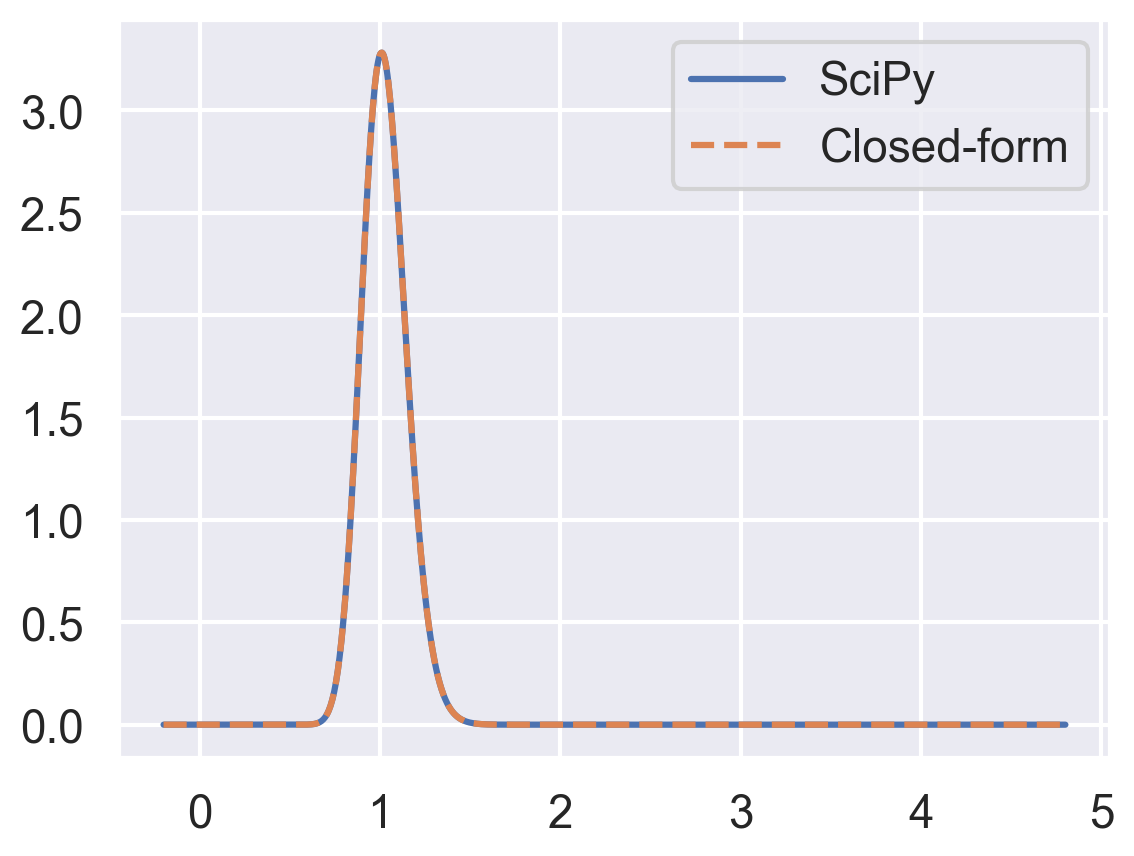

In [63]:
# Check PDF formula


def f_pdf(x, mu, sigma, delta):
    x = np.asarray(np.atleast_1d(x))
    pdf = np.zeros_like(x)
    mask = x > delta
    x_scaled = (np.log(x[mask] - delta) - mu) / sigma
    pdf[mask] = np.exp(-0.5 * x_scaled**2) / (
        (x[mask] - delta) * sigma * np.sqrt(2 * np.pi)
    )
    return pdf


mu = 0.2
sigma = 1e-1
shift = -0.2
xs = np.linspace(shift, shift + 5.0, 1000)
stats.lognorm.pdf(xs, s=sigma, scale=np.exp(mu), loc=shift)

fig, ax = plt.subplots()
ax.plot(
    xs,
    stats.lognorm.pdf(xs, s=sigma, scale=np.exp(mu), loc=shift),
    label="SciPy",
)
ax.plot(xs, f_pdf(xs, mu, sigma, shift), label="Closed-form", linestyle="--")
ax.legend()
plt.show()

In [64]:
# Sanity check: example on simulated data

true_mean, true_sigma, true_shift = 1.0, 0.5, 2.0
size = 10**5
data = np.exp(true_mean + true_sigma * np.random.randn(size)) + true_shift

# Fit shifted log normal
sigma, shift, scale = stats.lognorm.fit(data)

In [65]:
print("Fitted parameters:")
print(f"  Shape (sigma): {sigma:<.4f}  | {true_sigma:<.4f} (true)")
print(f"  Location (shift): {shift:<.4f}  | {true_shift:<.4f} (true)")
print(f"  Scale (scale): {scale:<.4f}  | {np.exp(true_mean):<.4f} (true)")

Fitted parameters:
  Shape (sigma): 0.5033  | 0.5000 (true)
  Location (shift): 2.0077  | 2.0000 (true)
  Scale (scale): 2.7065  | 2.7183 (true)


In [66]:
# grid for plotting
x_grid = np.linspace(min(data), max(data), 301)
# fitted pdf
pdf_vals = stats.lognorm.pdf(x_grid, s=sigma, scale=scale, loc=shift)

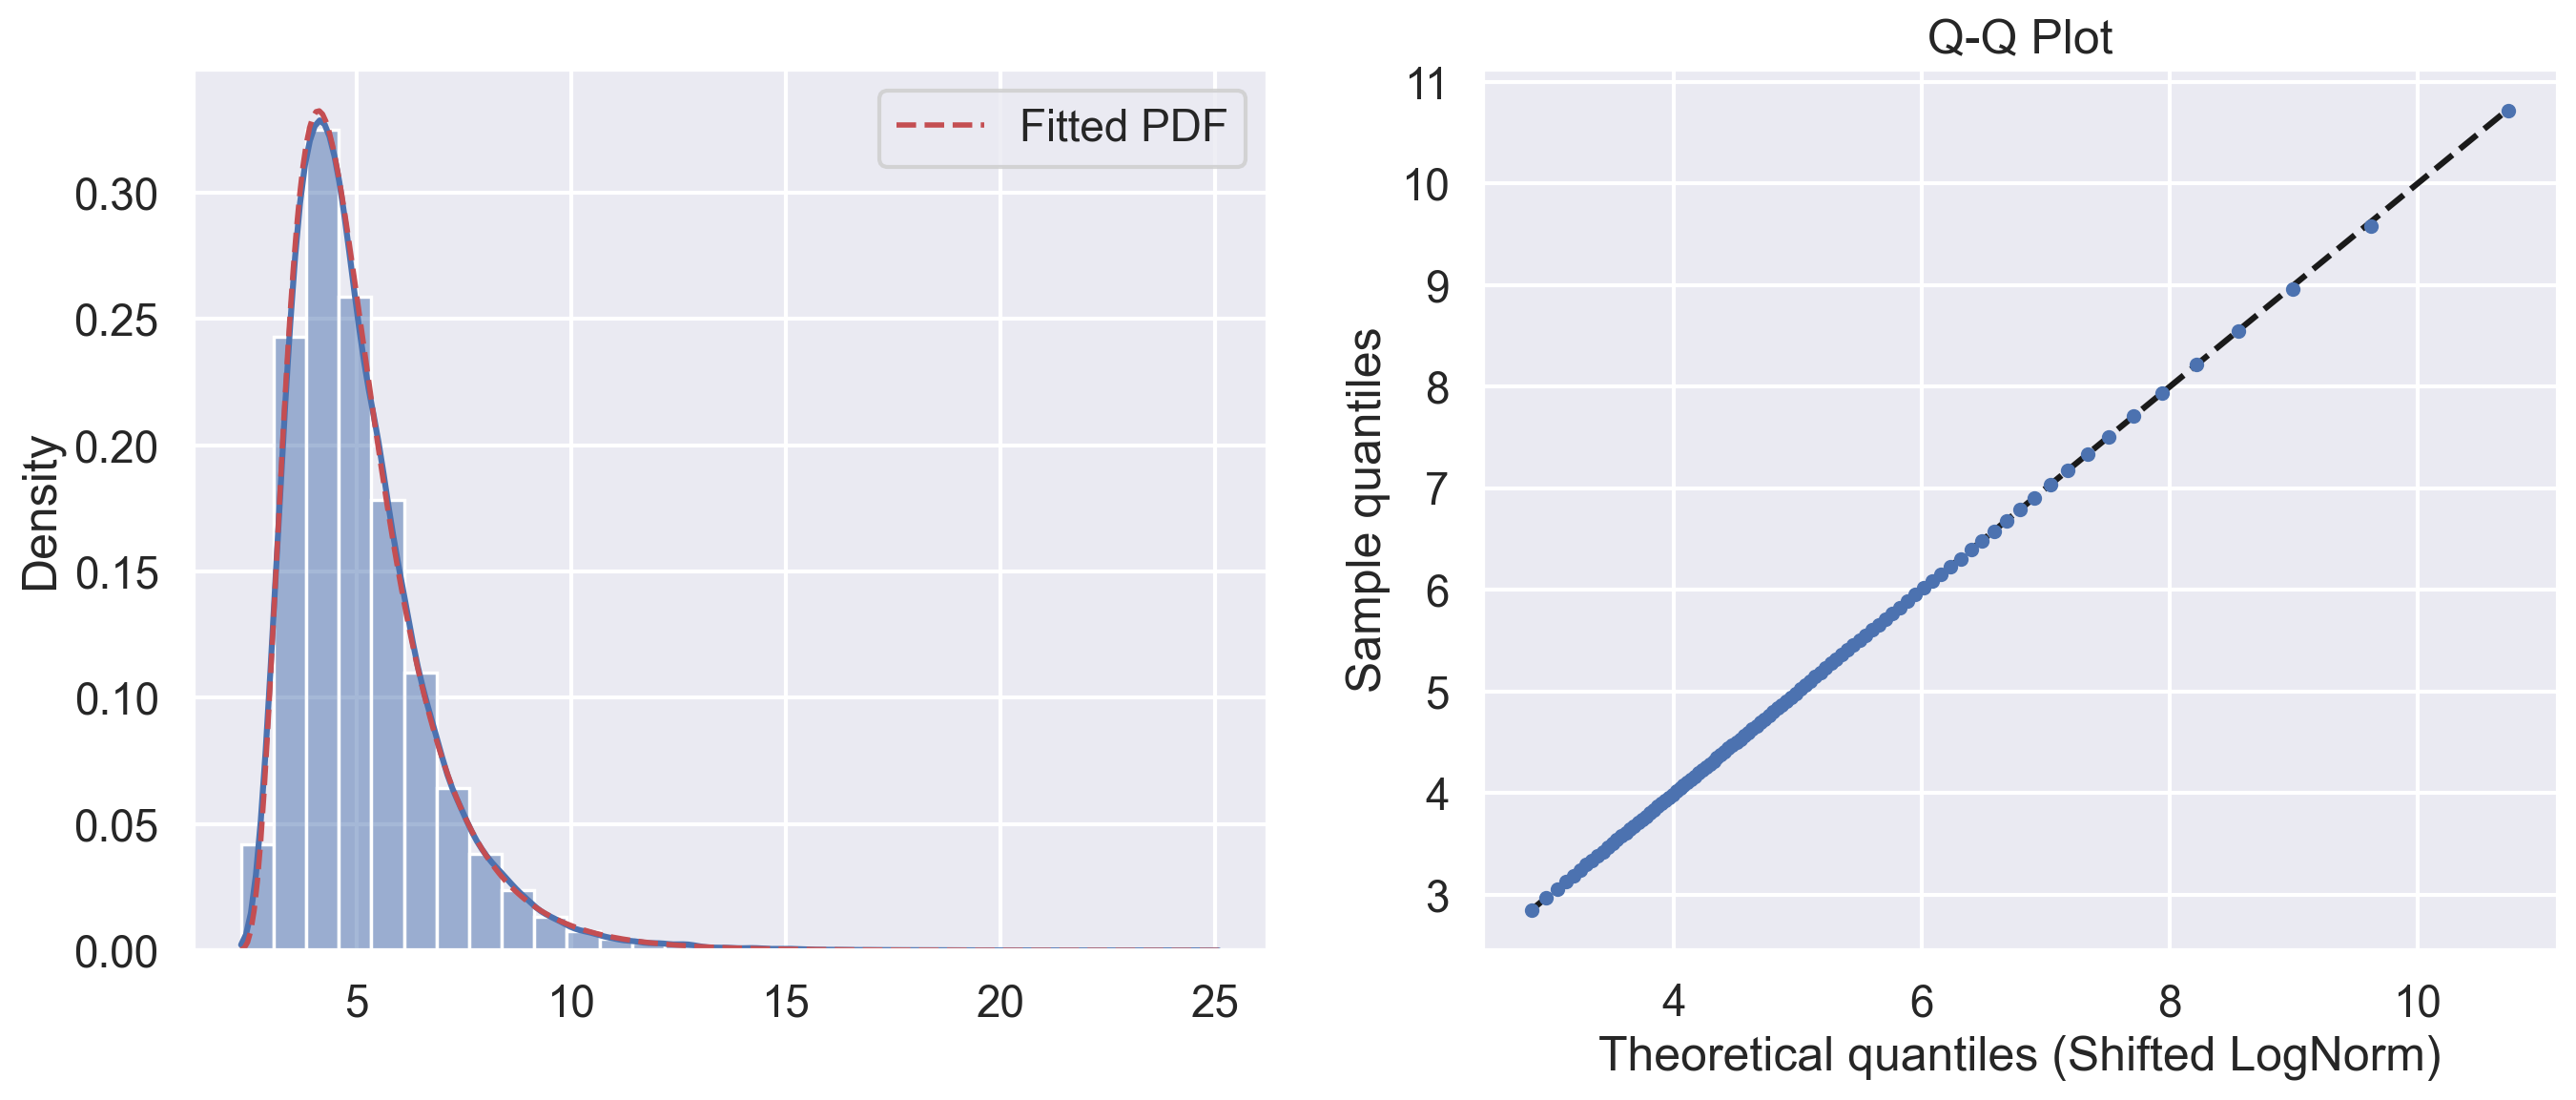

In [73]:
fig, ax = plt.subplots(1, 2, figsize=(2 * 8, 6))
sns.histplot(data, bins=30, kde=True, ax=ax[0], stat="density")
ax[0].plot(x_grid, pdf_vals, "r--", lw=2, label="Fitted PDF")
ax[0].legend()

quantiles = np.linspace(1e-2, 1 - 1e-2, 100)
lognorm_ppf = stats.lognorm.ppf(quantiles, s=sigma, scale=scale, loc=shift)

# Q-Q plot
ax[1].plot(lognorm_ppf, lognorm_ppf, "k--")
ax[1].plot(lognorm_ppf, np.quantile(data, quantiles), ".")
ax[1].set_xlabel("Theoretical quantiles (Shifted LogNorm)")
ax[1].set_ylabel("Sample quantiles")
ax[1].set_title("Q-Q Plot")

plt.show()

Now, do the same for the VIX

In [77]:
fitted_params = {}

for T_i in spx_expiries:
    vix_Ti = qrh_sim[T_i]["vix"]
    s, loc, scale = stats.lognorm.fit(vix_Ti)
    fitted_params[T_i] = {"shape": s, "location": loc, "scale": scale}

    print(f"Fitted parameters: (T={T_i:<.4f})")
    print(f"  Shape (sigma): {s:<.4f}")
    print(f"  Location (shift): {loc:<.4f}")
    print(f"  Scale (scale): {scale:<.4f}")

Fitted parameters: (T=0.0192)
  Shape (sigma): 0.5208
  Location (shift): 0.1463
  Scale (scale): 0.0345
Fitted parameters: (T=0.0383)
  Shape (sigma): 0.5616
  Location (shift): 0.1446
  Scale (scale): 0.0422
Fitted parameters: (T=0.0548)
  Shape (sigma): 0.5635
  Location (shift): 0.1433
  Scale (scale): 0.0481
Fitted parameters: (T=0.0767)
  Shape (sigma): 0.5867
  Location (shift): 0.1446
  Scale (scale): 0.0517


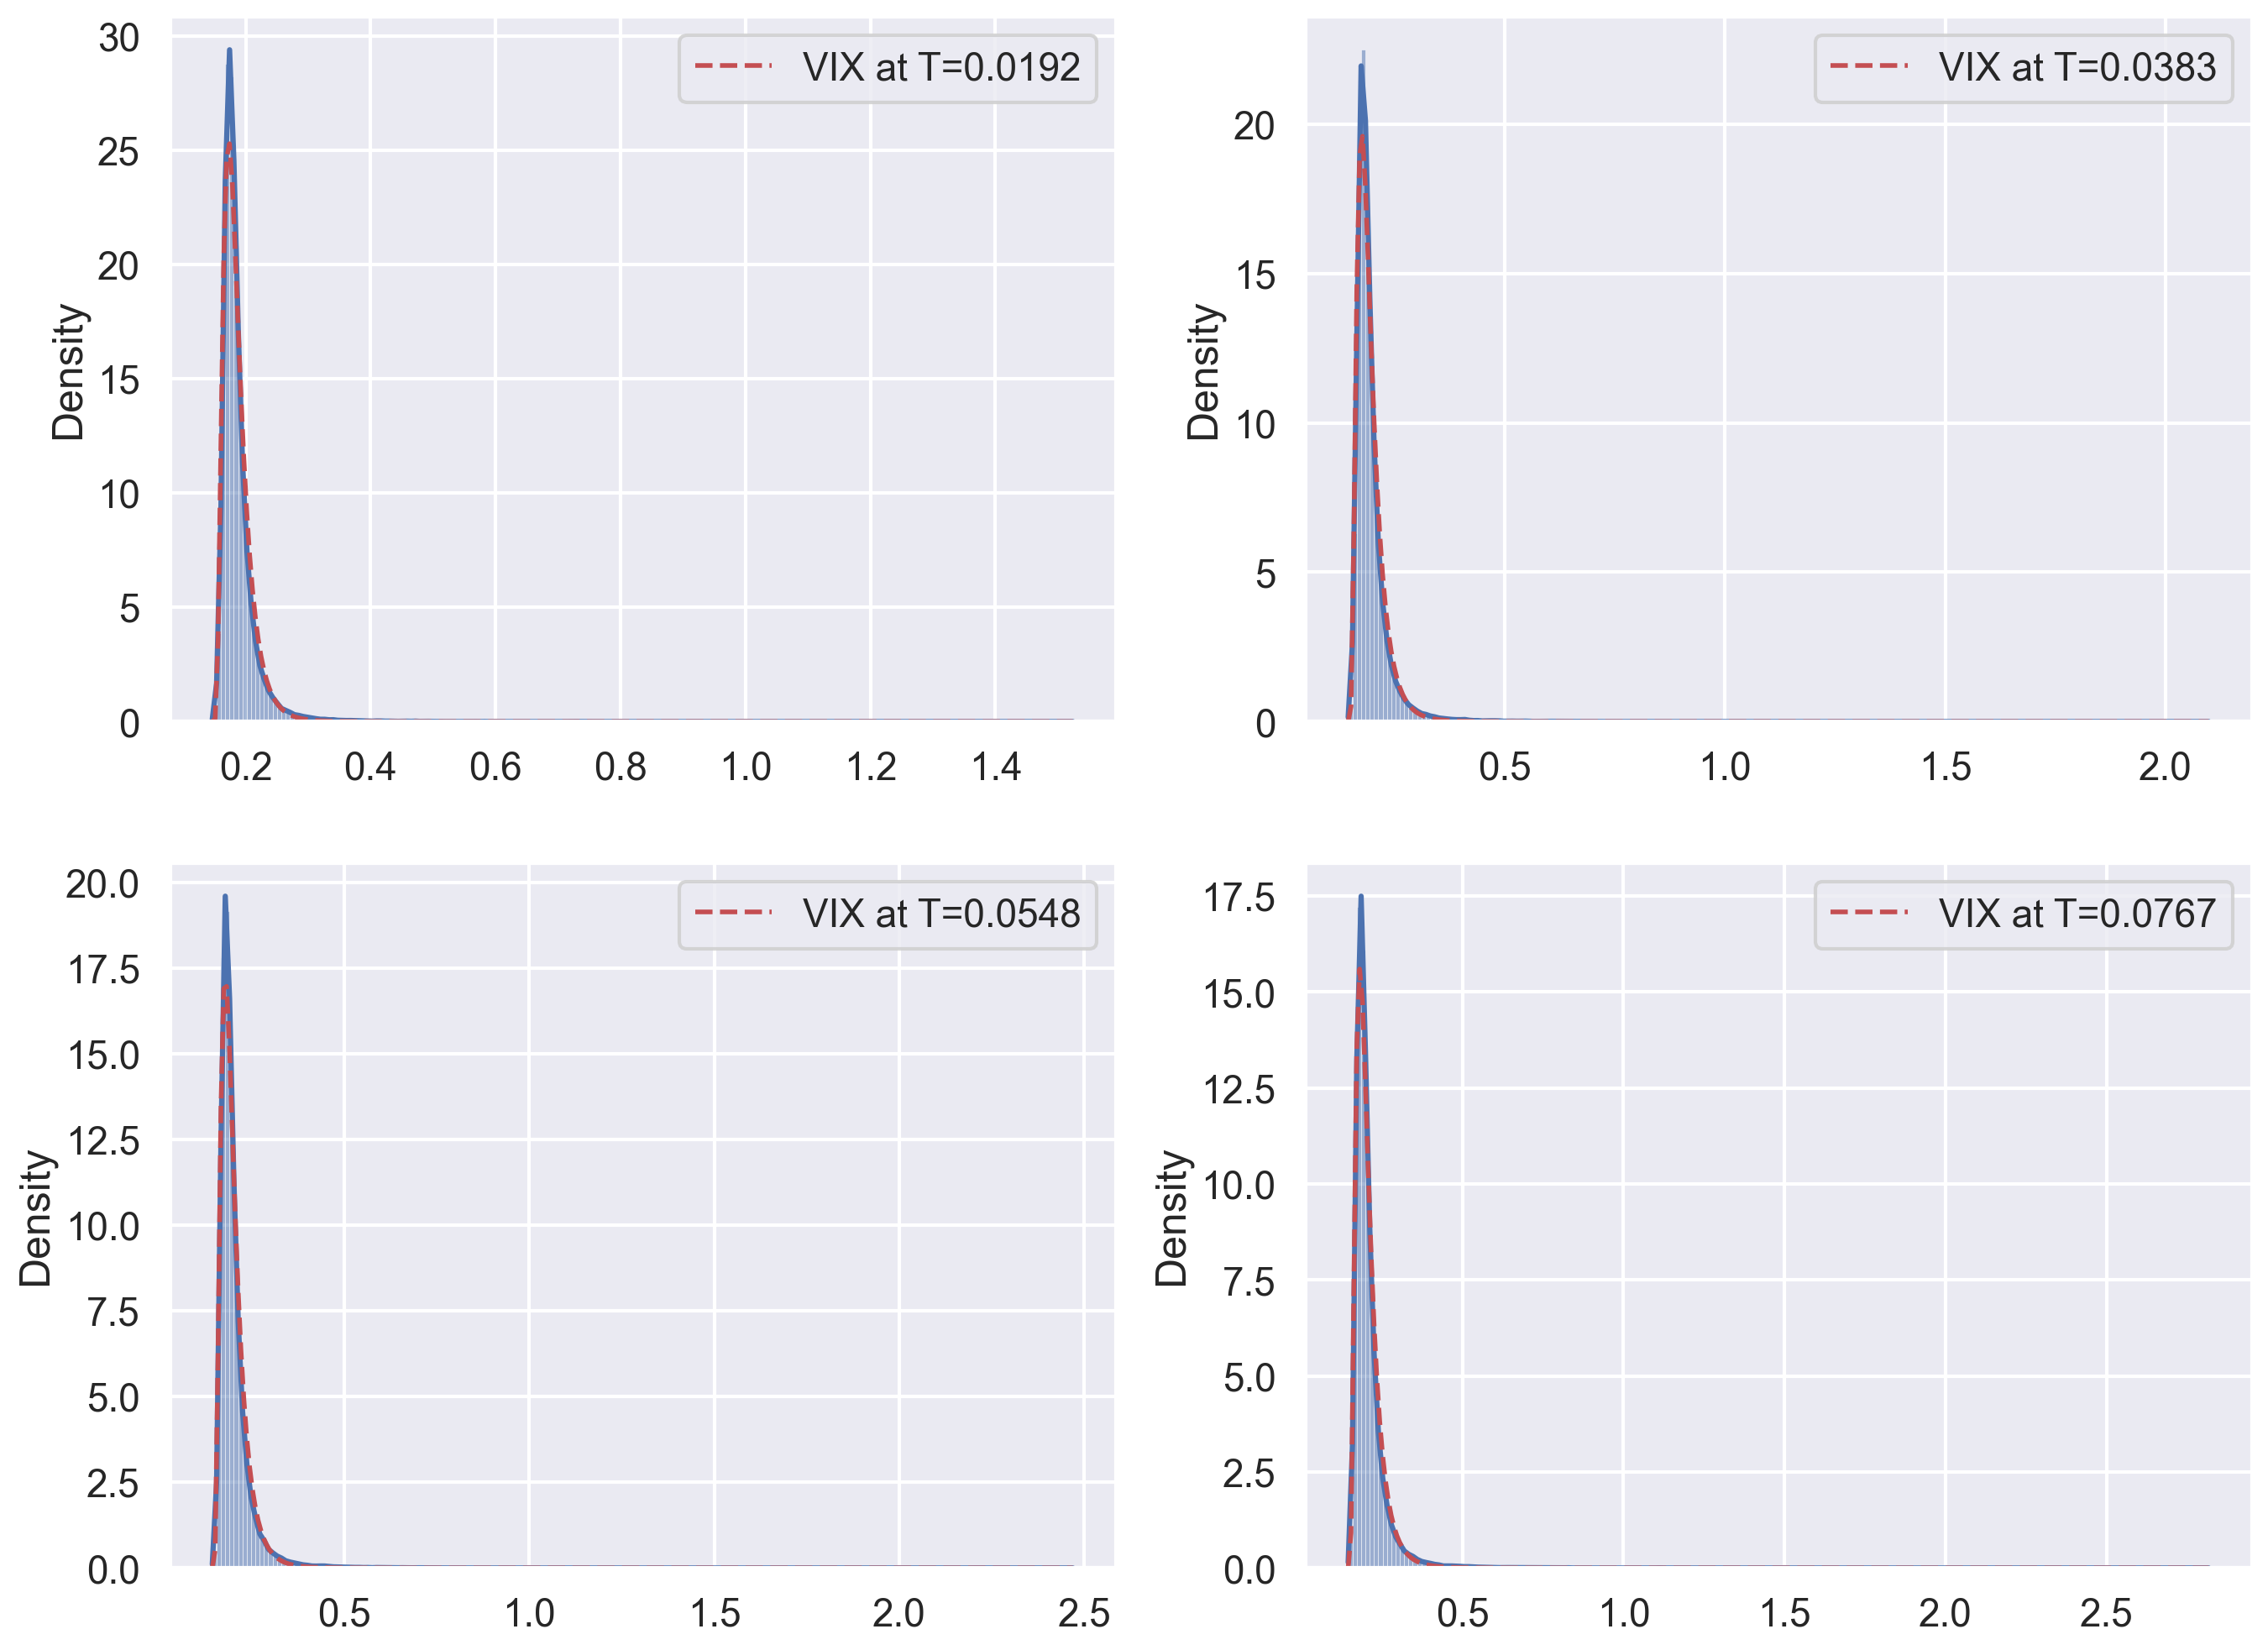

In [85]:
fig, ax = plt.subplots(2, 2, figsize=(2 * 8, 2 * 6))
for i, T_i in enumerate(spx_expiries):
    row, col = divmod(i, 2)
    ax_i = ax[row, col]
    vix_Ti = qrh_sim[T_i]["vix"]
    shape_i = fitted_params[T_i]["shape"]
    loc_i = fitted_params[T_i]["location"]
    scale_i = fitted_params[T_i]["scale"]

    x_grid_vix = np.linspace(np.min(vix_Ti), np.max(vix_Ti), 301)
    sns.histplot(vix_Ti, bins=200, ax=ax_i, kde=True, stat="density")
    ax_i.plot(
        x_grid_vix,
        stats.lognorm.pdf(x_grid_vix, shape_i, loc_i, scale_i),
        "r--",
        lw=2,
        label=f"VIX at T={T_i:<.4f}",
    )
    ax_i.legend()
plt.show()

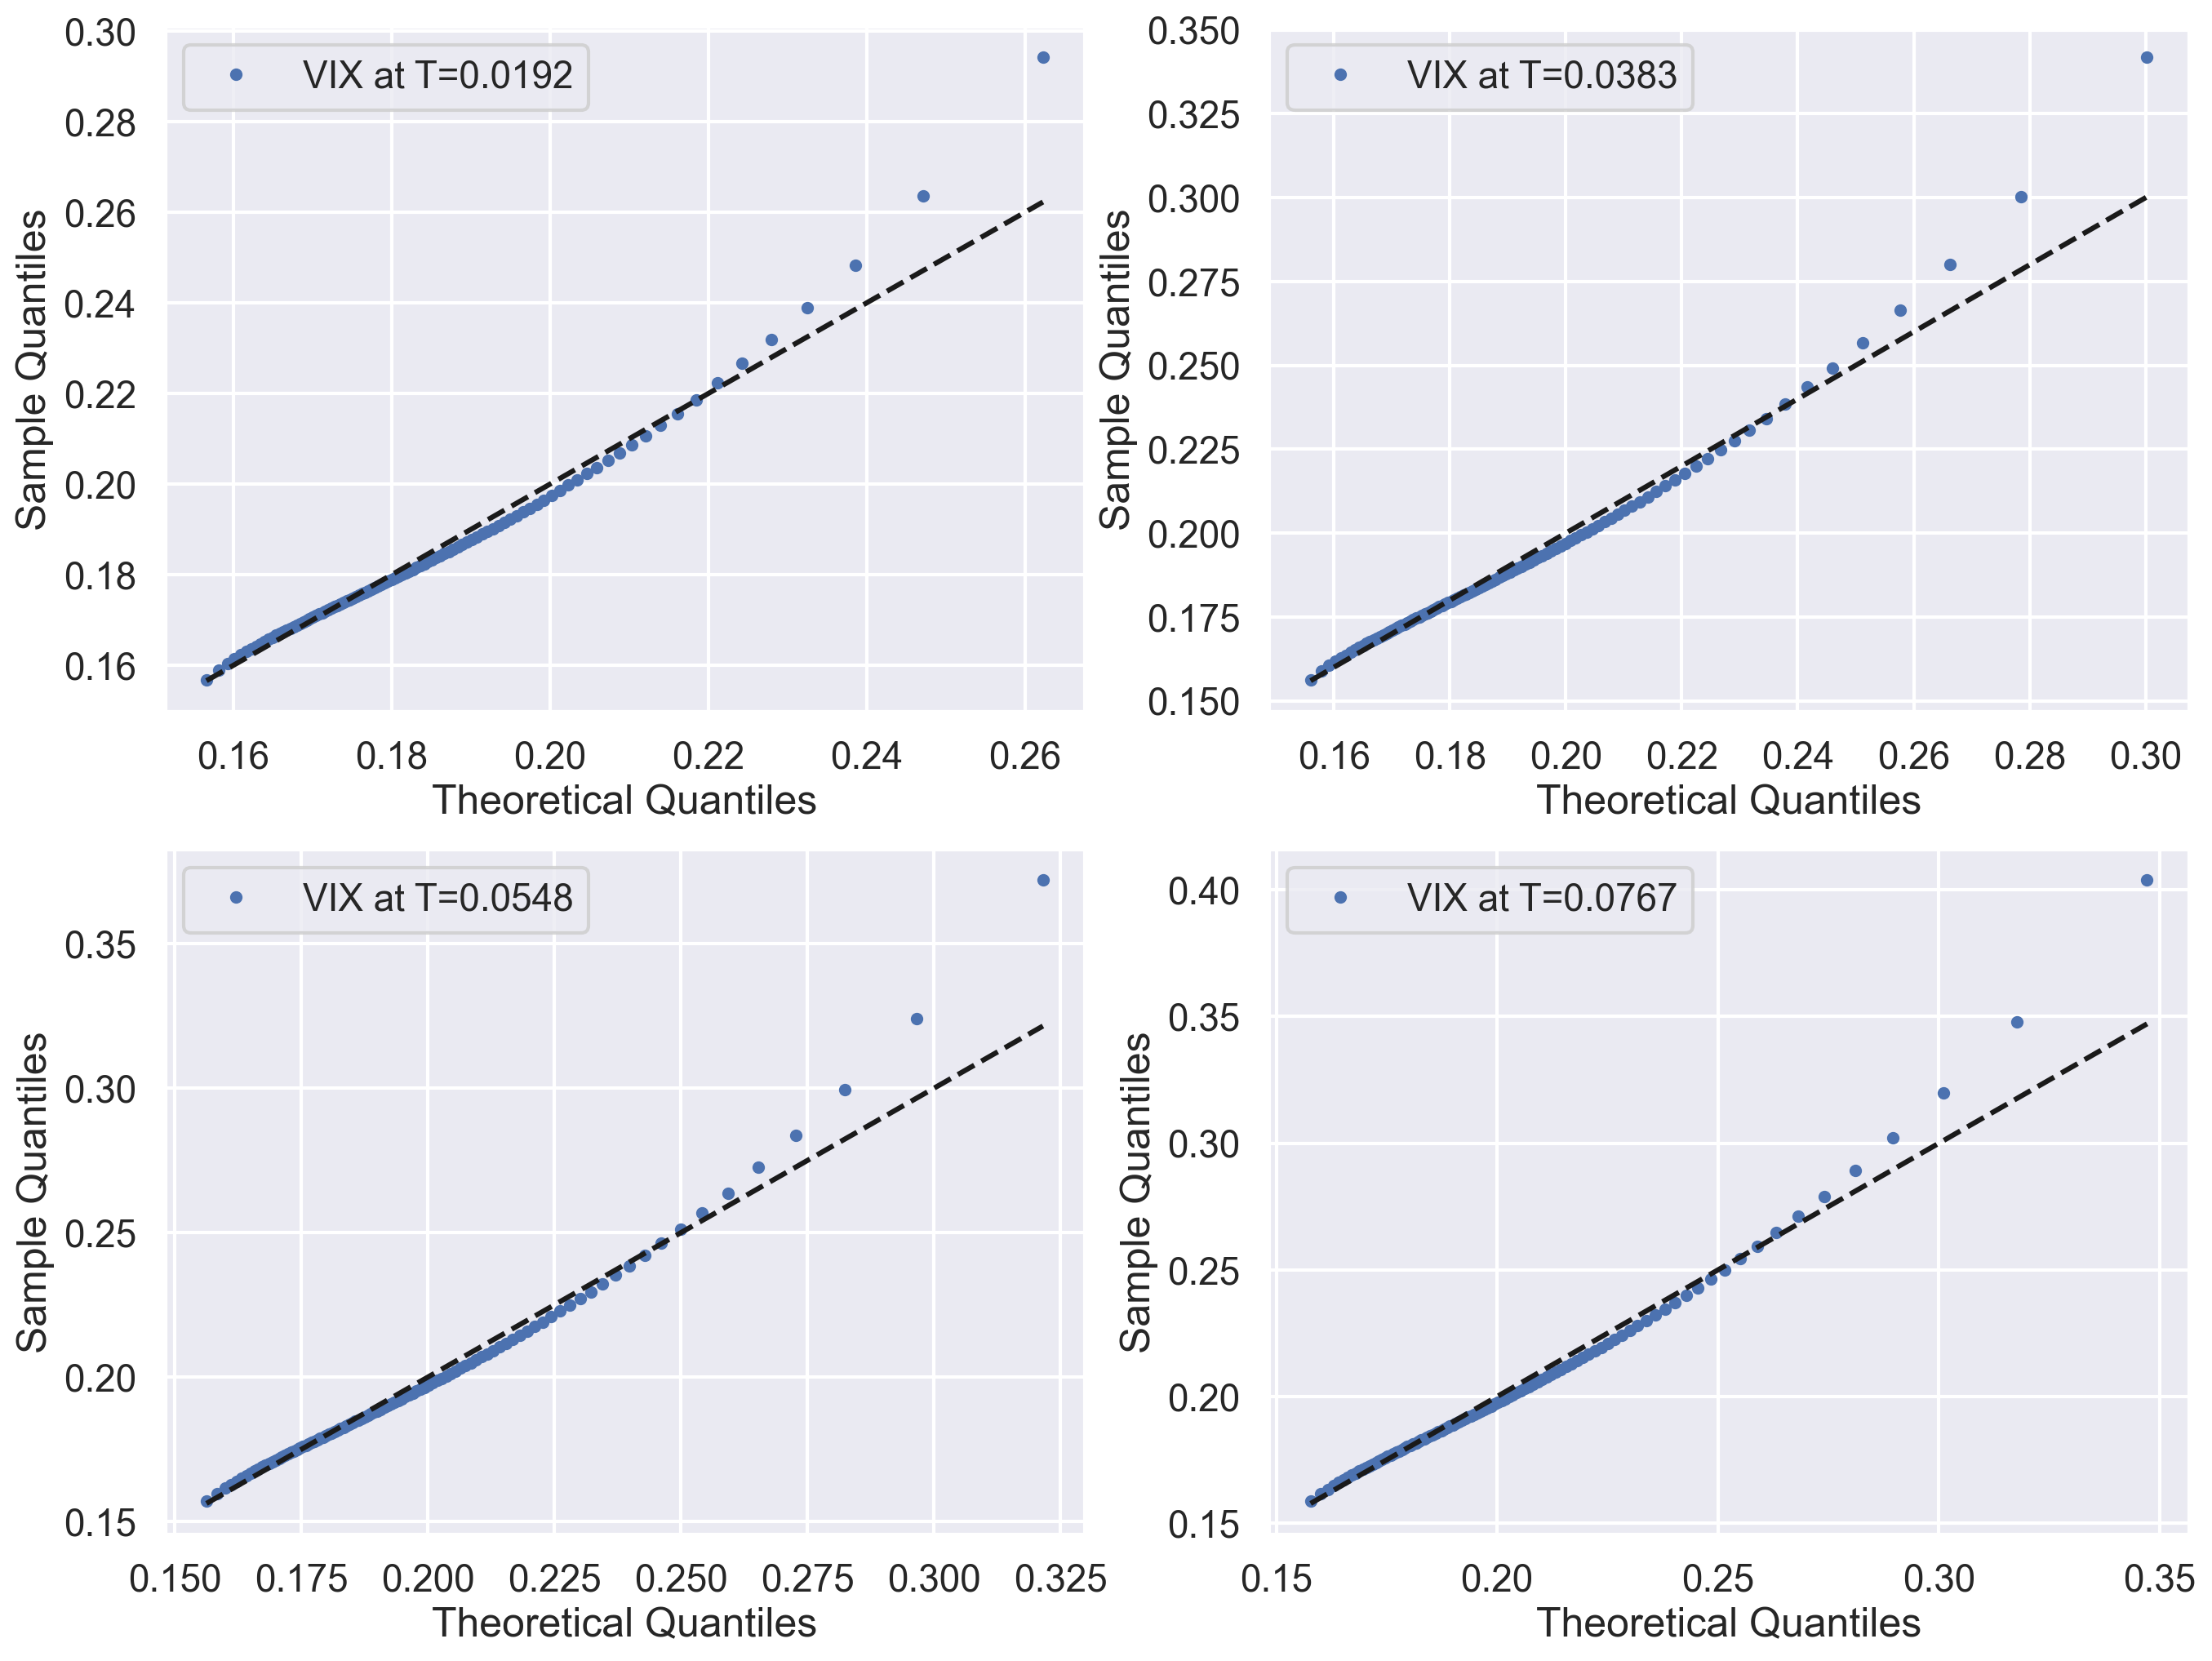

In [84]:
# Q-Q plot

quantiles = np.linspace(1e-2, 1 - 1e-2, 101)

fig, ax = plt.subplots(2, 2, figsize=(2 * 8, 2 * 6))
for i, T_i in enumerate(spx_expiries):
    row, col = divmod(i, 2)
    ax_i = ax[row, col]
    vix_Ti = qrh_sim[T_i]["vix"]
    shape_i = fitted_params[T_i]["shape"]
    loc_i = fitted_params[T_i]["location"]
    scale_i = fitted_params[T_i]["scale"]

    # plot
    lognorm_ppf = stats.lognorm.ppf(quantiles, shape_i, loc_i, scale_i)
    ax_i.plot(
        lognorm_ppf,
        np.quantile(vix_Ti, q=quantiles),
        ".",
        label=f"VIX at T={T_i:<.4f}",
    )
    ax_i.plot(lognorm_ppf, lognorm_ppf, "k--")
    ax_i.legend()
    ax_i.set_xlabel("Theoretical Quantiles")
    ax_i.set_ylabel("Sample Quantiles")
plt.show()

### Approximation of the VIX

In the QRH model, we made the approximation
$$
    \mathrm{VIX}_T^2
    =
    \frac{1}{\delta} 
    \int_0^\delta
    \big[    
        \bigl(y_0(T+u) + \sum_{k=1}^{n} a_k(T+u) \chi_k\bigr)^2 + c
    \big] w(u) du
$$

where:

- $w(u) = 1 + K_0(\delta-u)$

- $\chi_k = \int_{(k-1)\Delta}^{k\Delta} \sqrt{V_s} \, dW_s, \qquad 1 \leq k \leq n$

- $\Delta = T/n$ and $\delta = 30/365$.

We have that

$$
    \mathrm{VIX}_T^2
    =
    a_0(T) 
    + 
    \sum_{i=1}^{n} b_i(T) \chi_i 
    + 
    \sum_{i,j=1}^{n} c_{ij}(T) \chi_i \chi_j,
$$

where:

$$
    a_0(T) = \frac{1}{\delta} \int_0^\delta \big[ y_0(T+u)^2 + c \big] w(u) du,
$$

$$
    b_i(T) = \frac{2}{\delta} \int_0^\delta y_0(T+u) a_i(T+u) w(u) du,
$$

$$
    c_{ij}(T) = \frac{1}{\delta} \int_0^\delta a_i(T+u) a_j(T+u) w(u) du.
$$

We have also that

$$
    \mathbb{E}[\chi_k] = 0,
    \qquad
    \mathbb{E}[\chi_k^2] 
    = \int_{(k-1)\Delta}^{k\Delta} \xi_0(s) \, ds = \Delta \overline{\xi}_k,
$$

In [82]:
# test_0
np.random.seed(SEED)
n_paths = 1 * 10**6

a = 1.5
b = np.array([-1.0, 1.0])
C = np.array(
    [
        [1.0, 0.5],
        [0.5, 1.0],
    ]
)


Z = np.random.randn(b.shape[0], n_paths)

$S_n = a + b^\top Z + Z^\top C Z$ where $Z \sim \mathcal{N}(0, I)$ and $C$ is a symmetric matrix.

In [83]:
S_n = a + b @ Z + np.sum(Z * (C @ Z), axis=0)

In [84]:
# mean
mean_S_n = a + np.trace(C)

print(np.mean(S_n))
print(mean_S_n)

3.5019043520878026
3.5


In [85]:
# variance
variance_S_n = b.T @ b + 2 * np.trace(C @ C)

print(np.var(S_n))
print(variance_S_n)

7.014640381126598
7.0


In [86]:
# third cumulant = third central moment
third_cumulant_S_n = 6 * b.T @ C @ b + 8 * np.trace(C @ C @ C)

print(np.mean((S_n - np.mean(S_n)) ** 3))
print(third_cumulant_S_n)

33.962994823509646
34.0


In [92]:
# fourth_cumulant

fourth_cumulant_S_n = 48 * b.T @ C @ C @ b + 48 * np.trace(C @ C @ C @ C)

print(np.mean((S_n - np.mean(S_n)) ** 4) - 3 * np.var(S_n) ** 2)
print(fourth_cumulant_S_n)

266.2350318980734
270.0


Define $s_n = \sqrt{S_n}$

In [87]:
s_n = np.sqrt(S_n)

In [89]:
# approx mean s_n
print(np.mean(s_n))


approx_mean_s_n = (
    np.sqrt(mean_S_n)
    - variance_S_n / (8 * (mean_S_n) ** 1.5)
    + third_cumulant_S_n / (16 * (mean_S_n) ** 2.5)
)
print(approx_mean_s_n)

# it does not seem to work...

1.7558831612262396
1.8299213604411915


Can we use a Variance Gamma approx?

In [ ]:
from scipy import optimize

r = third_cumulant_S_n**2 / (variance_S_n * fourth_cumulant_S_n)


def func(u):
    return 3 * r * u**3 + (12 * r - 9) * u**2 + (18 * r - 12) * u + (6 * r - 4)


result = optimize.root_scalar(func, bracket=[-10, 10])

In [102]:
u = result.root

In [107]:
A = (third_cumulant_S_n**2 * (1 + u) ** 2) / (variance_S_n**2 * (2 + 3 * u) ** 2)
theta = np.sign(third_cumulant_S_n) * np.sqrt(A)
sig2 = u * A
k = variance_S_n / (theta**2 + sig2)
mu = mean_S_n - k * theta

In [109]:
print(mean_S_n)
print(mu + k * theta)

3.5
3.5


In [110]:
print(variance_S_n)
print(k * (theta**2 + sig2))

7.0
7.0


In [111]:
print(third_cumulant_S_n)
print(k * theta * (3 * sig2 + 2 * theta**2))

34.0
33.99999999999999


In [113]:
print(fourth_cumulant_S_n)
print(6 * k * theta**4 + 12 * k * theta**2 * sig2 + 3 * k * sig2**2)

270.0
295.1137272306703


In [118]:
rng = np.random.default_rng(SEED)

G = rng.gamma(shape=k, scale=1.0, size=n_paths)
W = rng.standard_normal(size=n_paths)
X = mu + theta * G + sig2**0.5 * np.sqrt(G) * W

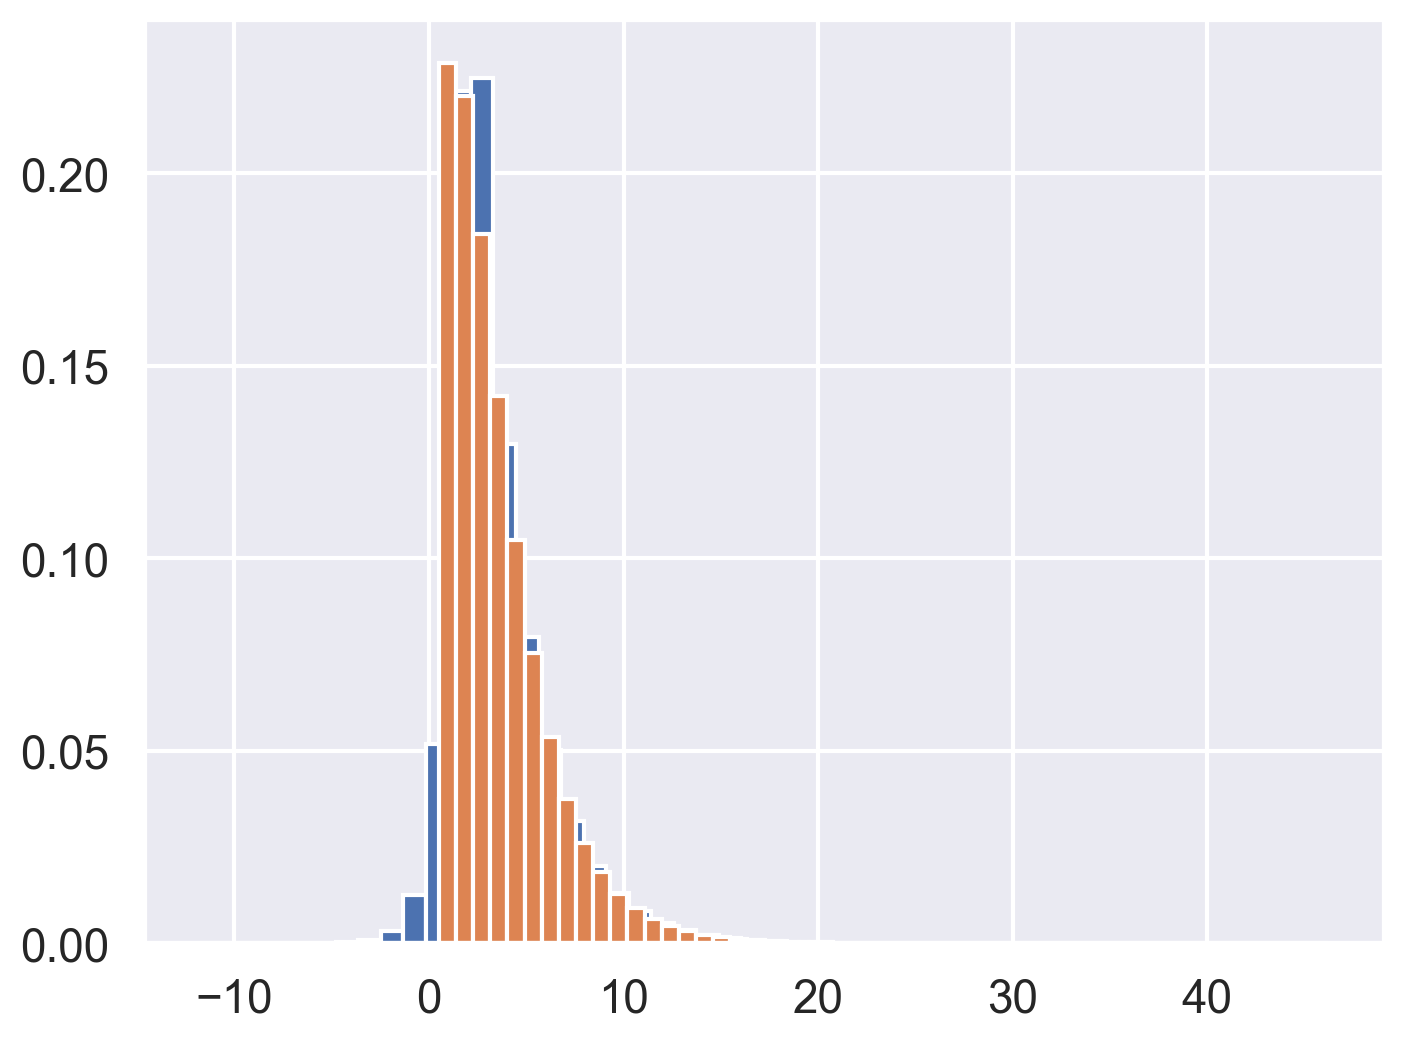

In [125]:
fig, ax = plt.subplots()
ax.hist(X, density=True, bins=50)
ax.hist(S_n, density=True, bins=50)
plt.show()